# Task 10 — Stress Testing & Project Conclusion
### QFI Internship · Market Risk Project · Phase 10
**Prepared by:** Arham Shah

---

**Objective.** VaR answers *"how bad is a normal bad day?"*. Stress testing answers *"what happens on a day the model has never seen?"*. We put **today's actual holdings** through real historical crises, hypothetical shocks and stressed volatility and correlation, and size every loss against the VaR model chosen in Task 9.

**What this notebook delivers**
- **Real crises replayed on today's holdings** using actual stock returns: 2008 GFC, 2011, 2018, COVID-2020, 2022, 2023, 2024, 2025, plus Black Monday 1987 via the index
- **Basel 2.5 stressed VaR**: the worst 250-day window since 2007, applied to today's book
- **Conditional scenarios** around single names and sectors, where unshocked stocks move by their estimated co-movement rather than staying flat
- **Volatility and correlation stress** applied directly to the Task 9 production model
- **Reverse stress testing**: the most likely way to lose 10%, 20% or 30%, and how often it actually happened
- A **risk-appetite dashboard**, an index-hedge analysis, and a **wrap-up of the whole Task 1–10 project**

> **Pipeline:** Task 1-3 Data & portfolio → Task 4-7 VaR models → Task 8 Backtesting → Task 9 Model selection → **Task 10 Stress testing**

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. Approach
| Family | Question | Method |
|---|---|---|
| Historical replay | *What would today's book lose if crisis X happened again?* | Actual daily stock returns over the episode applied to today's weights (full revaluation) |
| Stressed VaR | *What is our 99% VaR in the worst year on record?* | 250-day HS VaR of today's book, searched over 2007–2026 |
| Hypothetical market | *What if the S&P gaps −X%?* | Linear beta and **downside beta** (betas rise in sell-offs) |
| Conditional scenarios | *What if NVDA falls 40%?* | Shock some names; the others move by their conditional expectation $E[r_O\mid r_S]=\Sigma_{OS}\Sigma_{SS}^{-1}r_S$ |
| Vol / correlation | *What if volatility or correlations return to crisis levels?* | Rescale the Task 9 model's VaR by the stressed portfolio σ |
| Reverse stress | *What is the most likely market move that costs 20%?* | Minimum-Mahalanobis shock $z^*=-L\,\Sigma w/(w^\top\Sigma w)$, checked against history |

**Data gaps.** META (IPO 2012) and TSLA (IPO 2010) have no history for 2008, and no stock has data for 1987. For those, the stock's return is
proxied as *downside beta × S&P return*, and every table reports what share of the book was proxied.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

try:
    import yfinance as yf
except ImportError:
    %pip install -q yfinance
    import yfinance as yf

def yf_adj(symbols, start, end):
    px = yf.download(symbols, start=start, end=end, auto_adjust=False, progress=False)['Adj Close']
    return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

# ---- Stress-testing settings ----
INDEX_HIST_START = '1987-01-01'      # S&P 500 history (for Black Monday)
STOCK_HIST_START = '2007-01-01'      # stock history for the GFC and earlier crises
CRISIS_FILE      = 'Crisis_Prices.csv'
DOWN_DAY         = -0.01             # 'down market' day for downside betas
STRESS_LIMIT     = 0.20              # illustrative board limit: max stress loss = 20% of NAV
HEDGE_TARGET_BETA = 0.80             # illustrative hedge: bring downside beta to 0.80

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. The current book and the VaR yardstick

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


In [5]:
# ---- Shared volatility engine: EWMA (Task 5), GARCH (Task 6), GJR (Task 7) ----
from scipy.optimize import minimize
from scipy.special import gammaln
REFIT_EVERY, MIN_EST, EWMA_SEED = 21, 500, 30

def ewma_sigma(r, lam=EWMA_LAMBDA, seed=EWMA_SEED):
    e2 = np.asarray(r, float) ** 2; h0 = e2[:seed].mean()
    h = np.r_[h0, lfilter([1 - lam], [1, -lam], e2[:-1], zi=[lam * h0])[0]]
    return pd.Series(np.sqrt(h), index=r.index)

def backcast(e, n=75):
    w = 0.94 ** np.arange(min(n, len(e))); w /= w.sum()
    return float(w @ e[:len(w)] ** 2)

def vol_var(e, omega, alpha, beta, gamma=0.0):
    """h_t = omega + (alpha + gamma*1[e_{t-1}<0]) e_{t-1}^2 + beta h_{t-1}.  gamma = 0 -> GARCH(1,1)."""
    h0 = backcast(e)
    u = omega + (alpha + gamma * (e[:-1] < 0)) * e[:-1] ** 2
    return np.r_[h0, lfilter([1.0], [1.0, -beta], u, zi=[beta * h0])[0]]

def nll(p, x, dist, asym):
    mu, omega, alpha, beta = p[:4]
    gamma = p[4] if asym else 0.0
    e = x - mu
    h = np.maximum(vol_var(e, omega, alpha, beta, gamma), 1e-10)
    if dist == 'normal':
        ll = -0.5 * (np.log(2 * np.pi) + np.log(h) + e * e / h)
    else:
        nu = p[-1]
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
              - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(e * e / (h * (nu - 2))))
    return -ll.sum()

def fit_vol(r, dist='normal', asym=False, x0=None):
    """Gaussian or Student-t (Q)MLE of GARCH(1,1) or GJR-GARCH(1,1,1). Returns in percent units internally."""
    x = np.asarray(r, float) * 100
    v = x.var()
    tb = [(2.1, 100)] if dist == 't' else []
    if asym:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.02, 0.88, 0.10] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (0.0, 0.5), (0.0, 0.9999), (0.0, 0.5)] + tb
        con = lambda p: 0.9999 - p[2] - p[3] - 0.5 * p[4]
    else:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.08, 0.88] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (1e-6, 0.5), (0.0, 0.9999)] + tb
        con = lambda p: 0.9999 - p[2] - p[3]
    res = minimize(nll, x0, args=(x, dist, asym), method='SLSQP', bounds=bnds,
                   constraints={'type': 'ineq', 'fun': con}, options={'maxiter': 500, 'ftol': 1e-10})
    p = res.x
    gamma = p[4] if asym else 0.0
    pers = p[2] + p[3] + 0.5 * gamma
    k, ll = len(p), -res.fun
    return {'dist': dist, 'asym': asym, 'mu': p[0] / 100, 'omega': p[1] / 1e4, 'alpha': p[2], 'beta': p[3],
            'gamma': gamma, 'nu': p[-1] if dist == 't' else np.nan, 'persistence': pers,
            'long_run_vol_ann': np.sqrt(p[1] / 1e4 / (1 - pers) * TRADING_DAYS),
            'half_life': np.log(0.5) / np.log(pers), 'loglik': ll,
            'aic': 2 * k - 2 * ll, 'bic': k * np.log(len(x)) - 2 * ll, 'converged': bool(res.success), '_x': p}

def vol_sigma(r, P):
    """One-day-ahead conditional sigma_t (decimal) for the whole series under parameters P."""
    e = (np.asarray(r, float) - P['mu']) * 100
    return pd.Series(np.sqrt(vol_var(e, P['omega'] * 1e4, P['alpha'], P['beta'], P['gamma'])) / 100, index=r.index)

def vol_next(r, P):
    e = np.asarray(r, float) - P['mu']
    h = vol_sigma(r, P).iloc[-1] ** 2
    return float(np.sqrt(P['omega'] + (P['alpha'] + P['gamma'] * (e[-1] < 0)) * e[-1] ** 2 + P['beta'] * h))

def oos_fhs(r, dist, asym):
    """Filtered HS with the volatility model re-estimated every REFIT_EVERY days on past data only."""
    n = len(r)
    sig_oos = pd.Series(np.nan, index=r.index)
    panel = {(w, c): pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES']) for w in WINDOWS for c in CONFIDENCES}
    hist, x0 = [], None
    for b in range(MIN_EST, n, REFIT_EVERY):
        P = fit_vol(r.iloc[:b], dist, asym, x0); x0 = P['_x']
        end = min(b + REFIT_EVERY, n)
        rr = r.iloc[:end]
        s = vol_sigma(rr, P)
        zz = (rr / s).to_numpy()
        sig_oos.iloc[b:end] = s.iloc[b:end].values
        for (w, c), df in panel.items():
            lo = max(b, w)
            if lo >= end: continue
            sw = sliding_window_view(zz[lo - w:end - 1], w)
            q = np.quantile(sw, 1 - c, axis=1); m = sw <= q[:, None]
            df.iloc[lo:end, 0] = -q * s.iloc[lo:end].values
            df.iloc[lo:end, 1] = -(sw * m).sum(1) / m.sum(1) * s.iloc[lo:end].values
        hist.append({'Estimated through': r.index[b - 1], **{k: P[k] for k in
                     ['mu', 'omega', 'alpha', 'gamma', 'beta', 'nu', 'persistence', 'long_run_vol_ann', 'half_life', 'converged']}})
    return panel, sig_oos, pd.DataFrame(hist).set_index('Estimated through')

def best_dist(asym):
    fits = {d: fit_vol(returns, d, asym) for d in ['normal', 't']}
    return min(fits, key=lambda d: fits[d]['bic']), fits

def build_model(m):
    """Rebuild any model's forecast panel exactly as its own task does (used if a file is missing)."""
    if m == 'HS':
        return {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
    if m == 'EWMA':
        s = ewma_sigma(returns)
        return {(w, c): rolling_fhs(returns, s, w, c) for w in WINDOWS for c in CONFIDENCES}
    asym = (m == 'GJR')
    d, _ = best_dist(asym)
    return oos_fhs(returns, d, asym)[0]

COLORS.setdefault('GJR', '#9B2242')
print('Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).')

Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).


In [6]:
if os.path.exists('Portfolio_Weights.csv'):
    W = pd.read_csv('Portfolio_Weights.csv', index_col=0, parse_dates=True)[TICKERS].iloc[-1]
    WSRC = f'Task 3 actual weights on {returns.index[-1]:%d %b %Y} (drifted since the last rebalance)'
else:
    W = pd.Series(1 / len(TICKERS), index=TICKERS); WSRC = 'equal weights (Task 3 weights file not found)'
W = W / W.sum()
HOLD = W * NAV

# VaR yardstick = the production model chosen in Task 9
if os.path.exists('Model_Recommendation.json'):
    REC = json.load(open('Model_Recommendation.json'))
    MODEL, VAR1, ES1 = REC['label'], REC['next_day_VaR_usd'], REC['next_day_ES_usd']
    YSRC = 'Model_Recommendation.json (Task 9)'
else:
    d_, fits_ = best_dist(asym=True); P_ = fits_[d_]
    z_ = (returns - P_['mu']) / vol_sigma(returns, P_)
    v_, e_ = var_es(z_.iloc[-HEADLINE_W:], HEADLINE_CL); s_ = vol_next(returns, P_)
    MODEL, VAR1, ES1, YSRC = 'GJR-GARCH-FHS', v_ * s_ * NAV, e_ * s_ * NAV, 'recomputed (Task 9 file not found)'
print(f'Holdings : {WSRC}')
print(f'Yardstick: {MODEL} next-day {HEADLINE_CL:.0%} VaR {money(VAR1)} ({pct(VAR1 / NAV)}), ES {money(ES1)} [{YSRC}]')

Holdings : Task 3 actual weights on 24 Jul 2026 (drifted since the last rebalance)
Yardstick: GJR-GARCH-FHS next-day 99% VaR $210,395 (4.65%), ES $247,131 [Model_Recommendation.json (Task 9)]


## 3. Market data: the sample plus crisis history
The in-sample prices come from Task 1. Crisis history is downloaded once and cached in `Crisis_Prices.csv`.

In [7]:
if os.path.exists('Clean_Price_Matrix.csv') and os.path.exists(BENCH_FILE := 'Benchmark_prices.csv'):
    px_in = pd.read_csv('Clean_Price_Matrix.csv', index_col=0, parse_dates=True)[TICKERS]
    bm_in = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0].reindex(px_in.index)
else:
    bm_in = yf_adj([BENCHMARK], START_DATE, END_DATE).iloc[:, 0].dropna()
    px_in = yf_adj(TICKERS, START_DATE, END_DATE)[TICKERS].reindex(bm_in.index).ffill(limit=3).dropna()
    bm_in = bm_in.reindex(px_in.index)
R_in = px_in.pct_change().assign(MKT=bm_in.pct_change()).iloc[1:]

if os.path.exists(CRISIS_FILE):
    crisis = pd.read_csv(CRISIS_FILE, index_col=0, parse_dates=True); CSRC = 'cached file'
else:
    try:
        idx_old = yf_adj([BENCHMARK], INDEX_HIST_START, START_DATE).iloc[:, 0]
        stk_old = yf_adj(TICKERS, STOCK_HIST_START, START_DATE)
        crisis = stk_old.reindex(idx_old.index)[TICKERS].assign(MKT=idx_old)
        crisis.to_csv(CRISIS_FILE); CSRC = 'downloaded from Yahoo Finance'
    except Exception as ex:
        crisis = None; CSRC = f'unavailable ({ex}); pre-2020 scenarios fall back to beta overlays'

# returns are computed within each segment (avoids a splice jump between data vintages)
R_old = crisis.pct_change(fill_method=None).iloc[1:] if crisis is not None else pd.DataFrame(columns=TICKERS + ['MKT'])
R_all = pd.concat([R_old[R_old.index < R_in.index[0]], R_in]).sort_index()

# betas on the current regime (2020-2026); downside beta on S&P down days
mkt = R_in['MKT']
BETA = R_in[TICKERS].apply(lambda s: s.cov(mkt) / mkt.var())
dn = mkt < DOWN_DAY
BETA_DN = R_in.loc[dn, TICKERS].apply(lambda s: np.polyfit(mkt[dn], s, 1)[0])
R_fill = R_all[TICKERS].copy()
for t in TICKERS:
    R_fill[t] = R_fill[t].fillna(BETA_DN[t] * R_all['MKT'])        # proxy pre-IPO / pre-2007 days
first_real = R_all[TICKERS].apply(lambda s: s.first_valid_index())

book = pd.DataFrame({'Sector': pd.Series(UNIVERSE), 'Weight': W, 'Holding $': HOLD, 'Beta': BETA, 'Downside beta': BETA_DN,
                     'Daily vol (2020-26)': R_in[TICKERS].std(), 'Real data from': first_real.dt.date})
book.loc['PORTFOLIO'] = ['', 1.0, NAV, (W * BETA).sum(), (W * BETA_DN).sum(), np.nan, '']
BETA_P, BETA_DN_P = book.loc['PORTFOLIO', 'Beta'], book.loc['PORTFOLIO', 'Downside beta']
print(f'Crisis history: {CSRC} | combined returns {R_all.index[0]:%Y} -> {R_all.index[-1]:%Y} ({len(R_all):,} days)')
book.style.format({'Weight': '{:.1%}', 'Holding $': '${:,.0f}', 'Beta': '{:.2f}', 'Downside beta': '{:.2f}',
                   'Daily vol (2020-26)': '{:.2%}'}, na_rep='')

Crisis history: cached file | combined returns 1987 -> 2026 (9,963 days)


,Sector,Weight,Holding $,Beta,Downside beta,Daily vol (2020-26),Real data from
AAPL,Information Technology,11.4%,"$513,984",1.25,1.50,1.83%,2007-01-04
MSFT,Information Technology,10.1%,"$456,991",1.15,0.99,1.69%,2007-01-04
NVDA,Information Technology,10.2%,"$461,665",2.11,1.83,3.18%,2007-01-04
GOOGL,Communication Services,8.8%,"$399,574",1.27,1.00,1.96%,2007-01-04
META,Communication Services,10.4%,"$471,891",1.59,1.45,2.71%,2012-05-21
AMZN,Consumer Discretionary,9.6%,"$434,925",1.47,1.47,2.18%,2007-01-04
TSLA,Consumer Discretionary,7.4%,"$332,380",2.05,1.92,3.85%,2010-06-30
JPM,Financials,10.7%,"$484,080",0.88,1.01,1.58%,2007-01-04
XOM,Energy,11.3%,"$512,648",0.49,1.01,1.80%,2007-01-04
UNH,Health Care,10.0%,"$452,090",0.47,0.50,1.93%,2007-01-04


## 4. Historical crises replayed on today's book
Each episode runs from the close before the sell-off to the trough. The loss is what **today's holdings** would lose if they lived through the same daily stock moves, held through the window. For in-sample episodes we also show what the book actually lost at the time, with the weights it held then.

In [8]:
EPISODES = [
    ('Black Monday (Oct 1987)',          '1987-10-16', '1987-10-19'),
    ('GFC: Lehman to Nov-2008 trough',   '2008-09-12', '2008-11-20'),
    ('US downgrade (Aug 2011)',          '2011-07-22', '2011-08-08'),
    ('Volmageddon (Feb 2018)',           '2018-01-26', '2018-02-08'),
    ('Q4 2018 sell-off',                 '2018-09-20', '2018-12-24'),
    ('COVID crash (Feb-Mar 2020)',       '2020-02-19', '2020-03-23'),
    ('2022 inflation bear market',       '2022-01-03', '2022-10-12'),
    ('SVB banking stress (Mar 2023)',    '2023-03-08', '2023-03-13'),
    ('Yen carry unwind (Aug 2024)',      '2024-07-31', '2024-08-05'),
    ('Tariff shock (Apr 2025)',          '2025-04-02', '2025-04-08'),
]
rows = []
for name, s, e in EPISODES:
    win = R_fill.loc[(R_fill.index > s) & (R_fill.index <= e)]
    mk = R_all['MKT'].loc[win.index]
    if win.empty or mk.isna().all():
        continue
    cum = (1 + win).prod() - 1
    proxied = W[R_all[TICKERS].loc[win.index].isna().any()].sum()
    port = float((W * cum).sum())
    then = np.nan
    if pd.Timestamp(s) >= pf.index[0] - pd.Timedelta(days=5):
        v = raw['Value']; then = v.loc[:e].iloc[-1] / v.loc[:s].iloc[-1] - 1
    h = len(win)
    rows.append({'Scenario': name, 'Type': 'In-sample' if pd.Timestamp(s) >= R_in.index[0] else 'Pre-sample',
                 'From': win.index[0].date(), 'To': win.index[-1].date(), 'Days': h, 'S&P 500': (1 + mk).prod() - 1,
                 "Today's book": port, 'Loss $': -port * NAV, 'Book at the time': then, 'Proxied weight': proxied,
                 'x 1-day VaR': -port * NAV / VAR1, 'x √h-scaled VaR': -port * NAV / (VAR1 * np.sqrt(h)),
                 'Worst stock': cum.idxmin() if proxied < 0.5 else '-', 'Worst stock move': cum.min() if proxied < 0.5 else np.nan})
HIST = pd.DataFrame(rows).set_index('Scenario')

# worst realised windows for today's book anywhere in 2007-2026
port_hist = (R_fill.loc['2007':] * W).sum(1)
for k in (1, 5, 20):
    roll = np.expm1(np.log1p(port_hist).rolling(k).sum())
    HIST.loc[f'Worst {k}-day loss since 2007'] = {'Type': 'Worst window', 'From': roll.index[roll.index.get_loc(roll.idxmin()) - k + 1].date(),
        'To': roll.idxmin().date(), 'Days': k, 'S&P 500': np.expm1(np.log1p(R_all['MKT']).rolling(k).sum()).loc[roll.idxmin()],
        "Today's book": roll.min(), 'Loss $': -roll.min() * NAV, 'Book at the time': np.nan, 'Proxied weight': np.nan,
        'x 1-day VaR': -roll.min() * NAV / VAR1, 'x √h-scaled VaR': -roll.min() * NAV / (VAR1 * np.sqrt(k)),
        'Worst stock': '', 'Worst stock move': np.nan}
(HIST.sort_values('Loss $', ascending=False).style
     .format({'S&P 500': '{:.1%}', "Today's book": '{:.1%}', 'Loss $': '${:,.0f}', 'Book at the time': '{:.1%}',
              'Proxied weight': '{:.0%}', 'x 1-day VaR': '{:.1f}x', 'x √h-scaled VaR': '{:.1f}x', 'Worst stock move': '{:.0%}'}, na_rep='-')
     .background_gradient(subset=['Loss $'], cmap='Reds'))

,Type,From,To,Days,S&P 500,Today's book,Loss $,Book at the time,Proxied weight,x 1-day VaR,x √h-scaled VaR,Worst stock,Worst stock move
Scenario,,,,,,,,,,,,,
GFC: Lehman to Nov-2008 trough,Pre-sample,2008-09-15,2008-11-20,49,-39.9%,-42.9%,"$1,938,399",-,18%,9.2x,1.3x,TSLA,-66%
COVID crash (Feb-Mar 2020),Pre-sample,2020-02-20,2020-03-23,23,-33.9%,-34.3%,"$1,548,383",-,0%,7.4x,1.5x,TSLA,-53%
Worst 20-day loss since 2007,Worst window,2020-02-20,2020-03-18,20,-29.2%,-33.5%,"$1,513,544",-,-,7.2x,1.6x,,-
Black Monday (Oct 1987),Pre-sample,1987-10-19,1987-10-19,1,-20.5%,-25.6%,"$1,158,696",-,100%,5.5x,5.5x,-,-
2022 inflation bear market,In-sample,2022-01-04,2022-10-12,195,-25.4%,-25.1%,"$1,132,695",-30.3%,0%,5.4x,0.4x,META,-62%
Q4 2018 sell-off,Pre-sample,2018-09-21,2018-12-24,65,-19.8%,-24.1%,"$1,087,378",-,0%,5.2x,0.6x,NVDA,-52%
Worst 5-day loss since 2007,Worst window,2008-11-14,2008-11-20,5,-17.4%,-22.1%,"$999,933",-,-,4.8x,2.1x,,-
US downgrade (Aug 2011),Pre-sample,2011-07-25,2011-08-08,11,-16.8%,-16.4%,"$741,822",-,10%,3.5x,1.1x,META,-24%
Worst 1-day loss since 2007,Worst window,2020-03-16,2020-03-16,1,-12.0%,-13.6%,"$616,880",-,-,2.9x,2.9x,,-


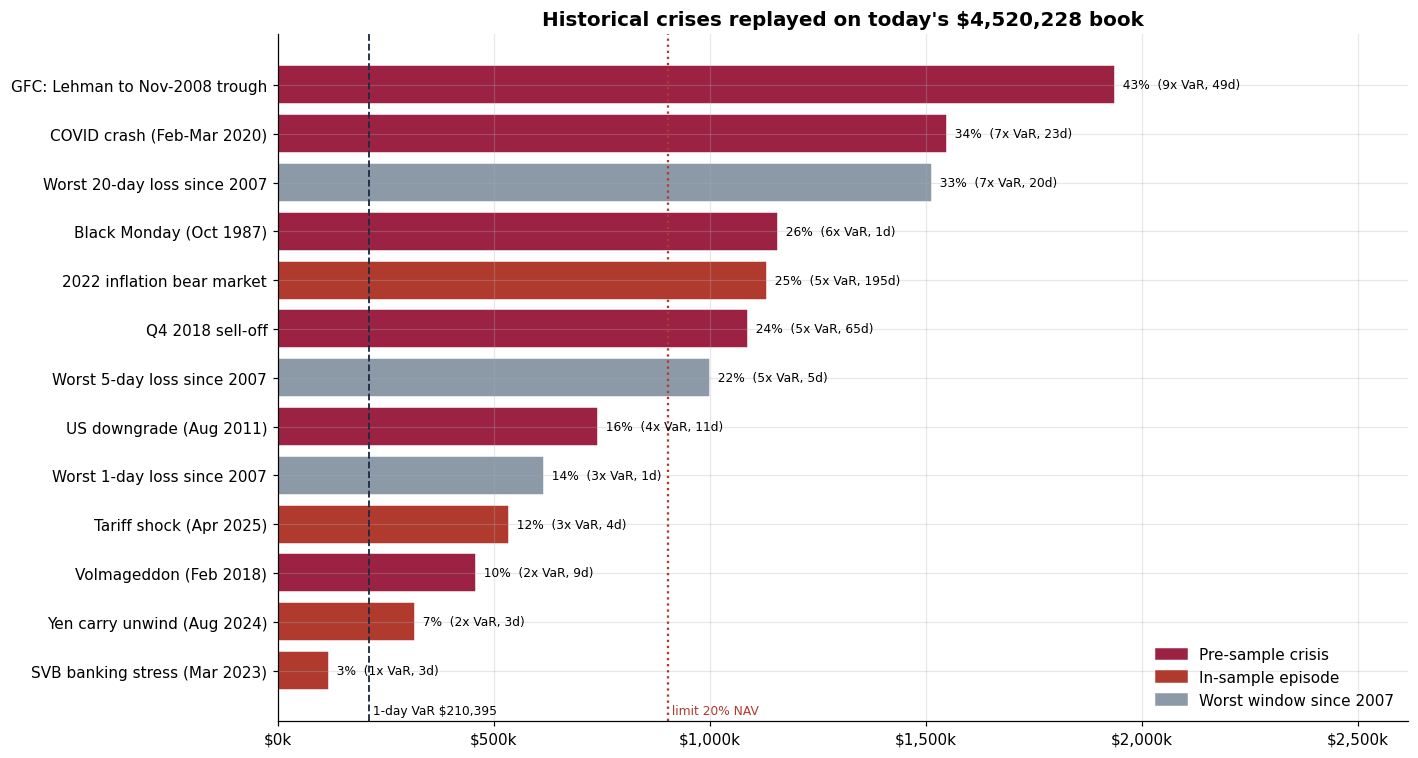

In [9]:
d = HIST.sort_values('Loss $')
col = d['Type'].map({'Pre-sample': COLORS['GJR'] if 'GJR' in COLORS else '#9B2242', 'In-sample': COLORS['loss'], 'Worst window': COLORS['muted']})
fig, ax = plt.subplots(figsize=(13, 7))
ax.barh(d.index, d['Loss $'], color=col, edgecolor='white')
ax.axvline(VAR1, color=COLORS['ink'], ls='--', lw=1.2); ax.text(VAR1, -0.9, f' 1-day VaR {money(VAR1)}', fontsize=8)
ax.axvline(STRESS_LIMIT * NAV, color=COLORS['loss'], ls=':', lw=1.5); ax.text(STRESS_LIMIT * NAV, -0.9, f' limit {STRESS_LIMIT:.0%} NAV', fontsize=8, color=COLORS['loss'])
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r['Loss $'], i, f"  {r['Loss $'] / NAV:.0%}  ({r['x 1-day VaR']:.0f}x VaR, {int(r['Days'])}d)", va='center', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#9B2242', label='Pre-sample crisis'), Patch(color=COLORS['loss'], label='In-sample episode'),
                   Patch(color=COLORS['muted'], label='Worst window since 2007')], loc='lower right')
ax.xaxis.set_major_formatter(usd_fmt); ax.set_xlim(0, d['Loss $'].max() * 1.35)
ax.set_title(f"Historical crises replayed on today's {money(NAV)} book")
plt.tight_layout(); plt.show()

## 5. Stressed VaR (Basel 2.5)
This is the 99% one-day HS VaR of **today's book**, computed over every 250-day window since 2007, with the worst window taken as the stressed VaR. Basel requires banks to hold capital against this number as well as current VaR.

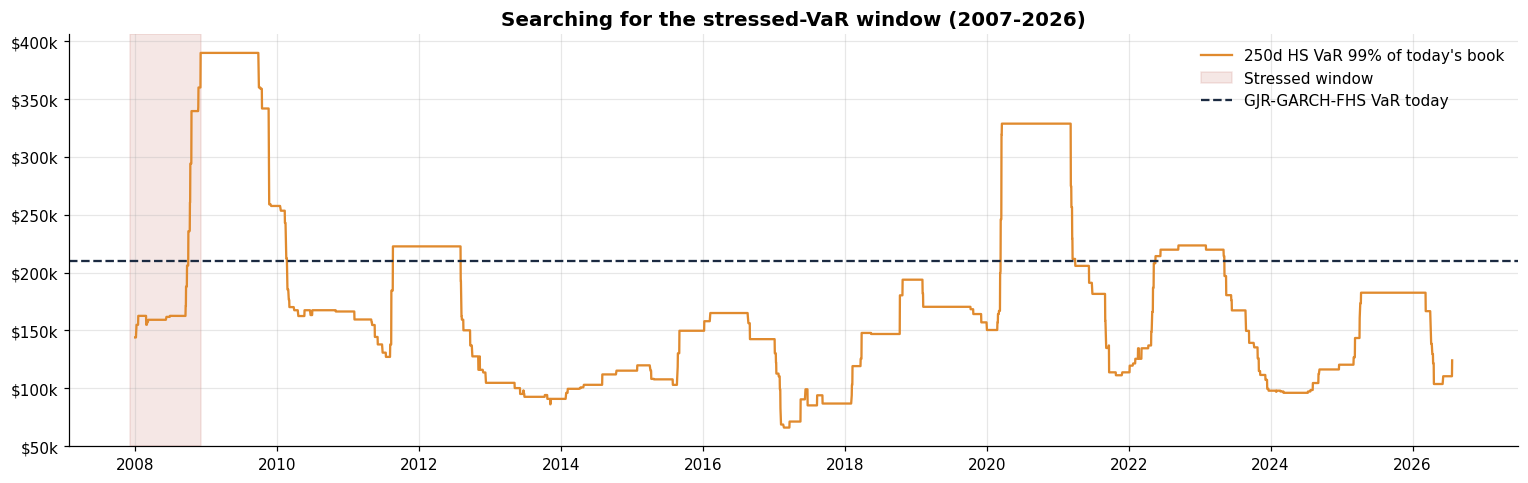

,Value
Stressed window,05 Dec 2007 -> 02 Dec 2008
Stressed VaR 99% (1d),0.0863
Stressed VaR $,"389,925.9272"
Stressed ES 97.5% $,"402,898.1953"
Current HS VaR 99% (1d),0.0275
GJR-GARCH-FHS VaR (Task 9),0.0465
sVaR / current model VaR,1.8533


In [10]:
ph = port_hist.dropna()
roll_var = rolling_hs(ph, 250, 0.99)['VaR']
roll_es = rolling_hs(ph, 250, 0.975)['ES']
end = roll_var.idxmax(); svar = roll_var.max()
start_w = ph.index[ph.index.get_loc(end) - 250]
cur_var = var_es(ph.iloc[-250:], 0.99)[0]
SV = pd.Series({'Stressed window': f'{start_w:%d %b %Y} -> {end:%d %b %Y}', 'Stressed VaR 99% (1d)': svar, 'Stressed VaR $': svar * NAV,
                'Stressed ES 97.5% $': roll_es.loc[end] * NAV, 'Current HS VaR 99% (1d)': cur_var,
                f'{MODEL} VaR (Task 9)': VAR1 / NAV, 'sVaR / current model VaR': svar * NAV / VAR1})
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(roll_var * NAV, color=COLORS['HS'], lw=1.5, label="250d HS VaR 99% of today's book")
ax.axvspan(start_w, end, color=COLORS['loss'], alpha=0.12, label='Stressed window')
ax.axhline(VAR1, color=COLORS['ink'], ls='--', label=f'{MODEL} VaR today')
ax.yaxis.set_major_formatter(usd_fmt); ax.legend(loc='upper right'); ax.set_title('Searching for the stressed-VaR window (2007-2026)')
plt.tight_layout(); plt.show()
SV.to_frame('Value')

## 6. Hypothetical shocks
### 6a. Market gaps: linear beta vs downside beta
In sell-offs stocks tend to fall *more* than their average beta suggests, which is why downside beta is the prudent choice.

In [11]:
grid = [-0.05, -0.10, -0.20, -0.30]
MKT = pd.DataFrame({'S&P shock': grid})
MKT['Loss $ (beta)'] = -np.array(grid) * BETA_P * NAV
MKT['Loss $ (downside beta)'] = -np.array(grid) * BETA_DN_P * NAV
MKT['% NAV (downside)'] = MKT['Loss $ (downside beta)'] / NAV
MKT['x VaR'] = MKT['Loss $ (downside beta)'] / VAR1
MKT['Breaches limit'] = np.where(MKT['% NAV (downside)'] > STRESS_LIMIT, 'YES', '')
print(f'Portfolio beta {BETA_P:.2f} | downside beta {BETA_DN_P:.2f}')
MKT.style.format({'S&P shock': '{:.0%}', 'Loss $ (beta)': '${:,.0f}', 'Loss $ (downside beta)': '${:,.0f}', '% NAV (downside)': '{:.1%}', 'x VaR': '{:.1f}x'}).hide(axis='index')

Portfolio beta 1.24 | downside beta 1.25


S&P shock,Loss $ (beta),Loss $ (downside beta),% NAV (downside),x VaR,Breaches limit
-5%,"$280,540","$283,065",6.3%,1.3x,
-10%,"$561,080","$566,131",12.5%,2.7x,
-20%,"$1,122,159","$1,132,262",25.0%,5.4x,YES
-30%,"$1,683,239","$1,698,393",37.6%,8.1x,YES


### 6b. Conditional single-name and sector scenarios
Shocking a few names and leaving the rest flat understates the loss, because the others usually fall too. Here the unshocked stocks and the S&P move by their
**conditional expectation** given the shock, $E[r_O\mid r_S]=\Sigma_{OS}\Sigma_{SS}^{-1}r_S$, estimated from 2020–2026 co-movements.

,S&P implied,Book move,Loss $,Loss $ if others flat,Spill-over adds,x VaR
S&P 500 −15% (index-led),-15.0%,-18.6%,"$841,619",$0,"$841,619",4.0x
Mega-cap tech / AI unwind,-11.4%,-16.6%,"$752,188","$614,951","$137,237",3.6x
NVDA collapse (−40%),-9.2%,-13.5%,"$610,169","$184,666","$425,503",2.9x
TSLA collapse (−40%),-6.1%,-9.6%,"$435,249","$132,952","$302,297",2.1x
UNH policy shock (−35%),-4.9%,-7.3%,"$328,928","$158,231","$170,697",1.6x
Banking crisis (JPM −35%),-13.7%,-16.0%,"$721,827","$169,428","$552,399",3.4x
Oil crash (XOM −30%),-5.1%,-6.4%,"$288,236","$153,794","$134,441",1.4x
"Rotation: tech −20%, value +5%",-7.9%,-12.1%,"$545,424","$475,365","$70,059",2.6x


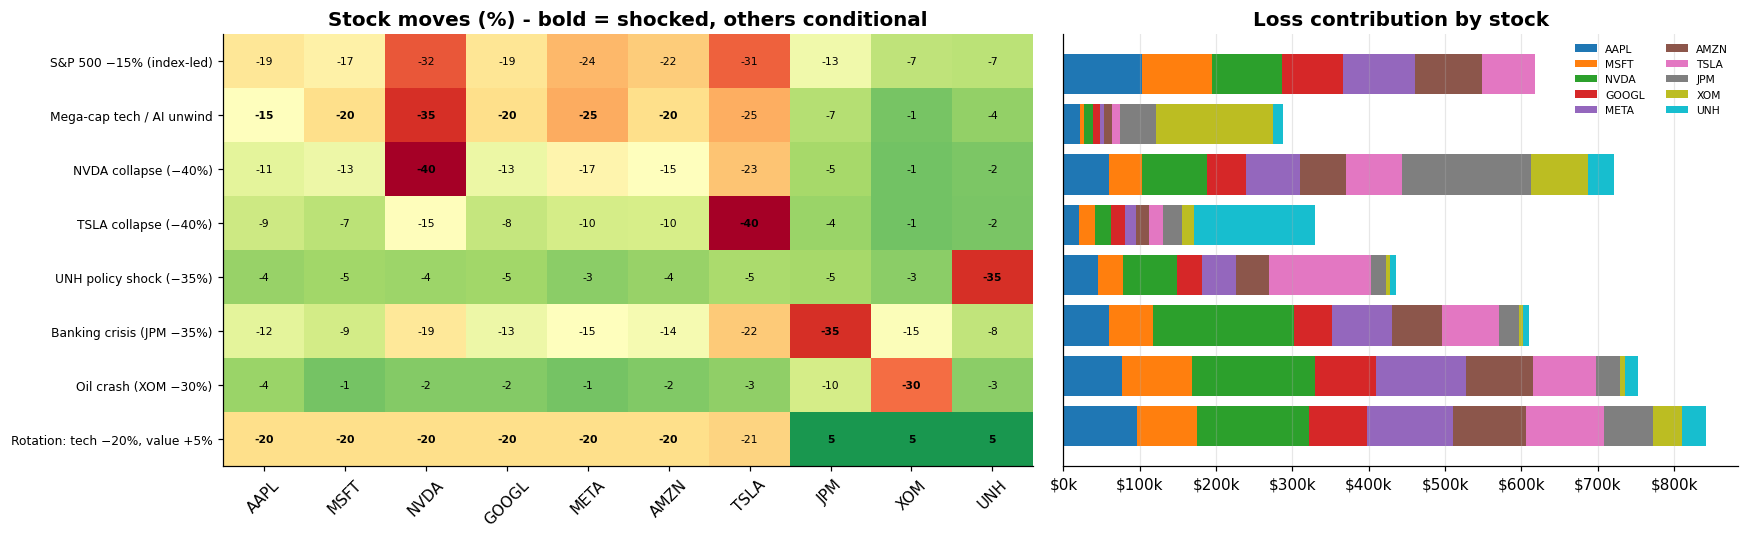

In [12]:
COLS = TICKERS + ['MKT']
SIG = R_in[COLS].cov()
def conditional(shocks):
    S = list(shocks); O = [c for c in COLS if c not in S]
    s = np.array([shocks[k] for k in S])
    mo = SIG.loc[O, S].values @ np.linalg.solve(SIG.loc[S, S].values, s)
    return pd.concat([pd.Series(s, index=S), pd.Series(mo, index=O)])[COLS]

TECH = ['AAPL', 'MSFT', 'NVDA', 'GOOGL', 'META', 'AMZN']
SCEN = {
    'S&P 500 −15% (index-led)':         {'MKT': -0.15},
    'Mega-cap tech / AI unwind':         {'NVDA': -0.35, 'META': -0.25, 'MSFT': -0.20, 'GOOGL': -0.20, 'AMZN': -0.20, 'AAPL': -0.15},
    'NVDA collapse (−40%)':              {'NVDA': -0.40},
    'TSLA collapse (−40%)':              {'TSLA': -0.40},
    'UNH policy shock (−35%)':           {'UNH': -0.35},
    'Banking crisis (JPM −35%)':         {'JPM': -0.35},
    'Oil crash (XOM −30%)':              {'XOM': -0.30},
    'Rotation: tech −20%, value +5%':    {**{t: -0.20 for t in TECH}, 'JPM': 0.05, 'XOM': 0.05, 'UNH': 0.05},
}
moves = pd.DataFrame({k: conditional(v) for k, v in SCEN.items()}).T
naive = pd.Series({k: -sum(W[t] * x for t, x in v.items() if t in W) * NAV for k, v in SCEN.items()})
COND = pd.DataFrame({'S&P implied': moves['MKT'], 'Book move': moves[TICKERS] @ W,
                     'Loss $': -(moves[TICKERS] @ W) * NAV, 'Loss $ if others flat': naive})
COND['Spill-over adds'] = COND['Loss $'] - COND['Loss $ if others flat']
COND['x VaR'] = COND['Loss $'] / VAR1
display(COND.style.format({'S&P implied': '{:.1%}', 'Book move': '{:.1%}', 'Loss $': '${:,.0f}', 'Loss $ if others flat': '${:,.0f}',
                           'Spill-over adds': '${:,.0f}', 'x VaR': '{:.1f}x'}).background_gradient(subset=['Loss $'], cmap='Reds'))

contrib = moves[TICKERS].mul(W) * NAV
fig, (a0, a1) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.2, 1]})
im = a0.imshow(moves[TICKERS].values * 100, cmap='RdYlGn', vmin=-40, vmax=10, aspect='auto')
a0.set_xticks(range(len(TICKERS)), TICKERS, rotation=45); a0.set_yticks(range(len(moves)), moves.index, fontsize=8)
for i in range(moves.shape[0]):
    for j, t in enumerate(TICKERS):
        a0.text(j, i, f'{moves[t].iloc[i] * 100:.0f}', ha='center', va='center', fontsize=7,
                fontweight='bold' if t in SCEN[moves.index[i]] else 'normal')
a0.grid(False); a0.set_title('Stock moves (%) - bold = shocked, others conditional')
bottom = np.zeros(len(contrib))
for t, cc in zip(TICKERS, plt.get_cmap('tab10').colors):
    a1.barh(contrib.index, -contrib[t].clip(upper=0), left=bottom, color=cc, label=t); bottom += -contrib[t].clip(upper=0).values
a1.set_yticks([]); a1.xaxis.set_major_formatter(usd_fmt); a1.legend(fontsize=7, ncol=2); a1.set_title('Loss contribution by stock')
plt.tight_layout(); plt.show()

## 7. Volatility and correlation stress on the production model
The chosen model is volatility-scaled FHS, so its VaR scales with σ. We rescale today's VaR by the ratio of stressed to current portfolio σ:
- **Volatility**: GJR volatility goes back to its sample peak, or doubles.
- **Correlation**: the stock correlations become those of the stressed-VaR window, or all equal 1 (no diversification at all).

In [13]:
dj, fj = best_dist(asym=True); PJ = fj[dj]
sig_j = vol_sigma(returns, PJ); s_now = vol_next(returns, PJ)
vols = R_in[TICKERS].iloc[-250:].std()
C_now = R_in[TICKERS].iloc[-250:].corr()
C_str = R_fill.loc[start_w:end].corr()
sp = lambda C: float(np.sqrt(W @ (np.outer(vols, vols) * C.values) @ W))
s0 = sp(C_now)
VC = pd.DataFrame([
    ('Today (model VaR)', 1.0),
    (f'GJR vol back to its peak ({sig_j.idxmax():%b %Y})', sig_j.max() / s_now),
    ('Volatility doubles', 2.0),
    (f'Correlations of the stressed window', sp(C_str) / s0),
    ('All correlations = 1', float(W @ vols) / s0),
    ('Peak vol AND stressed correlations', sig_j.max() / s_now * sp(C_str) / s0),
], columns=['Scenario', 'VaR multiplier']).set_index('Scenario')
VC['Stressed 1-day VaR $'] = VC['VaR multiplier'] * VAR1
VC['Stressed 1-day ES $'] = VC['VaR multiplier'] * ES1
VC['% NAV'] = VC['Stressed 1-day VaR $'] / NAV
display(VC.style.format({'VaR multiplier': '{:.2f}x', 'Stressed 1-day VaR $': '${:,.0f}', 'Stressed 1-day ES $': '${:,.0f}', '% NAV': '{:.1%}'}))
print(f'Diversification currently removes {1 - s0 / float(W @ vols):.0%} of stand-alone risk; '
      f'average pairwise correlation {C_now.values[np.triu_indices(10, 1)].mean():.2f} now vs {C_str.values[np.triu_indices(10, 1)].mean():.2f} in the stressed window.')

,VaR multiplier,Stressed 1-day VaR $,Stressed 1-day ES $,% NAV
Scenario,,,,
Today (model VaR),1.00x,"$210,395","$247,131",4.7%
GJR vol back to its peak (Apr 2025),2.17x,"$455,706","$535,276",10.1%
Volatility doubles,2.00x,"$420,790","$494,263",9.3%
Correlations of the stressed window,1.64x,"$344,751","$404,947",7.6%
All correlations = 1,2.02x,"$425,177","$499,417",9.4%
Peak vol AND stressed correlations,3.55x,"$746,717","$877,099",16.5%


Diversification currently removes 51% of stand-alone risk; average pairwise correlation 0.15 now vs 0.61 in the stressed window.


## 8. Reverse stress test
**8a. How far must the market fall?** Using downside beta, for a set of loss triggers.

**8b. The most plausible way to lose L.** Among all combinations of stock moves that cost L, the most likely one under the covariance Σ is
$z^*=-\frac{L}{\text{NAV}}\frac{\Sigma w}{w^\top\Sigma w}$. Its distance $d=\frac{L/\text{NAV}}{\sqrt{h\,w^\top\Sigma w}}$ is the loss in portfolio-σ units over h days.
We then check the **historical frequency**: how often since 2007 today's book actually lost at least L within h days.

,Loss $,S&P fall needed (downside beta)
1-day VaR (Task 9),"$210,395",-3.7%
10% of NAV,"$452,023",-8.0%
Board limit 20%,"$904,046",-16.0%
30% of NAV,"$1,356,068",-24.0%


Loss,Horizon (days),Distance (σ),Normal probability,Times it happened since 2007 (windows),Distinct episodes,Last time
10%,1,7.1,6.2e-13,2,2,2020-03-16
10%,5,3.2,7.5e-04,33,21,2025-04-08
10%,20,1.6,5.6e-02,195,54,2025-04-23
20%,1,14.2,4.5e-46,0,0,-
20%,5,6.4,1.1e-10,2,2,2008-11-20
20%,20,3.2,7.5e-04,19,8,2020-03-23
30%,1,21.3,5.5e-101,0,0,-
30%,5,9.5,8.2e-22,0,0,-
30%,20,4.8,9.5e-07,4,2,2020-03-20


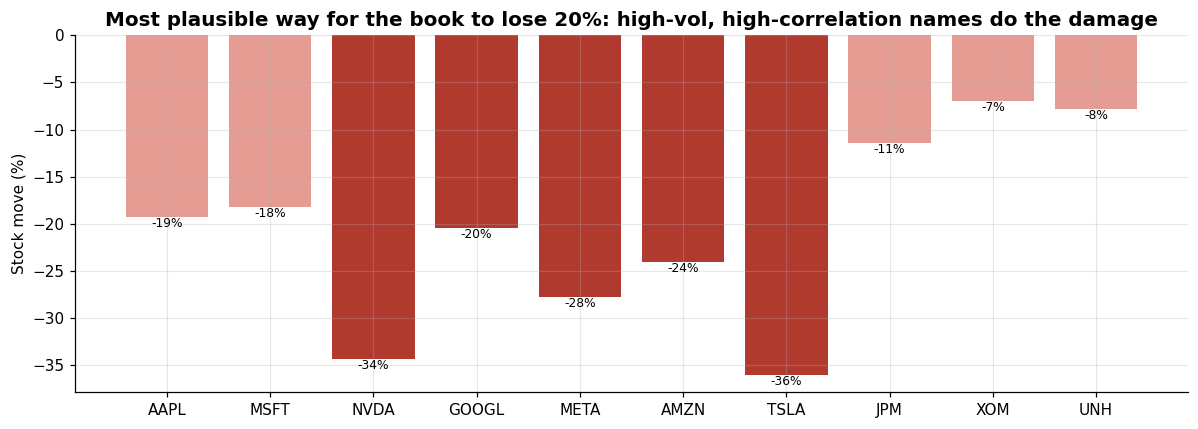

Normal probabilities are tiny, but history shows these losses DO happen: that gap is exactly the fat-tail risk VaR models underweight.


In [14]:
trig = {'1-day VaR (Task 9)': VAR1, '10% of NAV': 0.10 * NAV, f'Board limit {STRESS_LIMIT:.0%}': STRESS_LIMIT * NAV, '30% of NAV': 0.30 * NAV}
REV = pd.DataFrame({'Loss $': trig}).assign(**{'S&P fall needed (downside beta)': lambda x: x['Loss $'] / (BETA_DN_P * NAV)})
display(REV.style.format({'Loss $': '${:,.0f}', 'S&P fall needed (downside beta)': '-{:.1%}'}))

Sig_s = R_in[TICKERS].cov().values; wv = W.values
sig_p = float(np.sqrt(wv @ Sig_s @ wv))
rows = []
for L in [0.10, 0.20, 0.30]:
    for h in [1, 5, 20]:
        dist = L / (sig_p * np.sqrt(h))
        hl = np.expm1(np.log1p(port_hist).rolling(h).sum())
        rows.append({'Loss': f'{L:.0%}', 'Horizon (days)': h, 'Distance (σ)': dist, 'Normal probability': stats.norm.sf(dist),
                     'Times it happened since 2007 (windows)': int((hl <= -L).sum()),
                     'Distinct episodes': int(((hl <= -L) & ~(hl <= -L).shift(1, fill_value=False)).sum()),
                     'Last time': hl[hl <= -L].index.max().date() if (hl <= -L).any() else '-'})
RS = pd.DataFrame(rows)
display(RS.style.format({'Distance (σ)': '{:.1f}', 'Normal probability': '{:.1e}'}).hide(axis='index'))
zstar = pd.Series(-0.20 * (Sig_s @ wv) / (wv @ Sig_s @ wv), index=TICKERS)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(TICKERS, zstar * 100, color=[COLORS['loss'] if v < -0.2 else '#E59C93' for v in zstar])
for i, v in enumerate(zstar * 100): ax.text(i, v, f'{v:.0f}%', ha='center', va='top', fontsize=8)
ax.set_ylabel('Stock move (%)'); ax.set_title('Most plausible way for the book to lose 20%: high-vol, high-correlation names do the damage')
plt.tight_layout(); plt.show()
print('Normal probabilities are tiny, but history shows these losses DO happen: that gap is exactly the fat-tail risk VaR models underweight.')

## 9. Risk appetite dashboard and an index hedge
Every scenario on one chart against an **illustrative** board limit (stress loss ≤ 20% of NAV). We then size a short S&P 500 futures hedge that brings downside beta to the target, and show what it does to the stress losses and to the historical return.

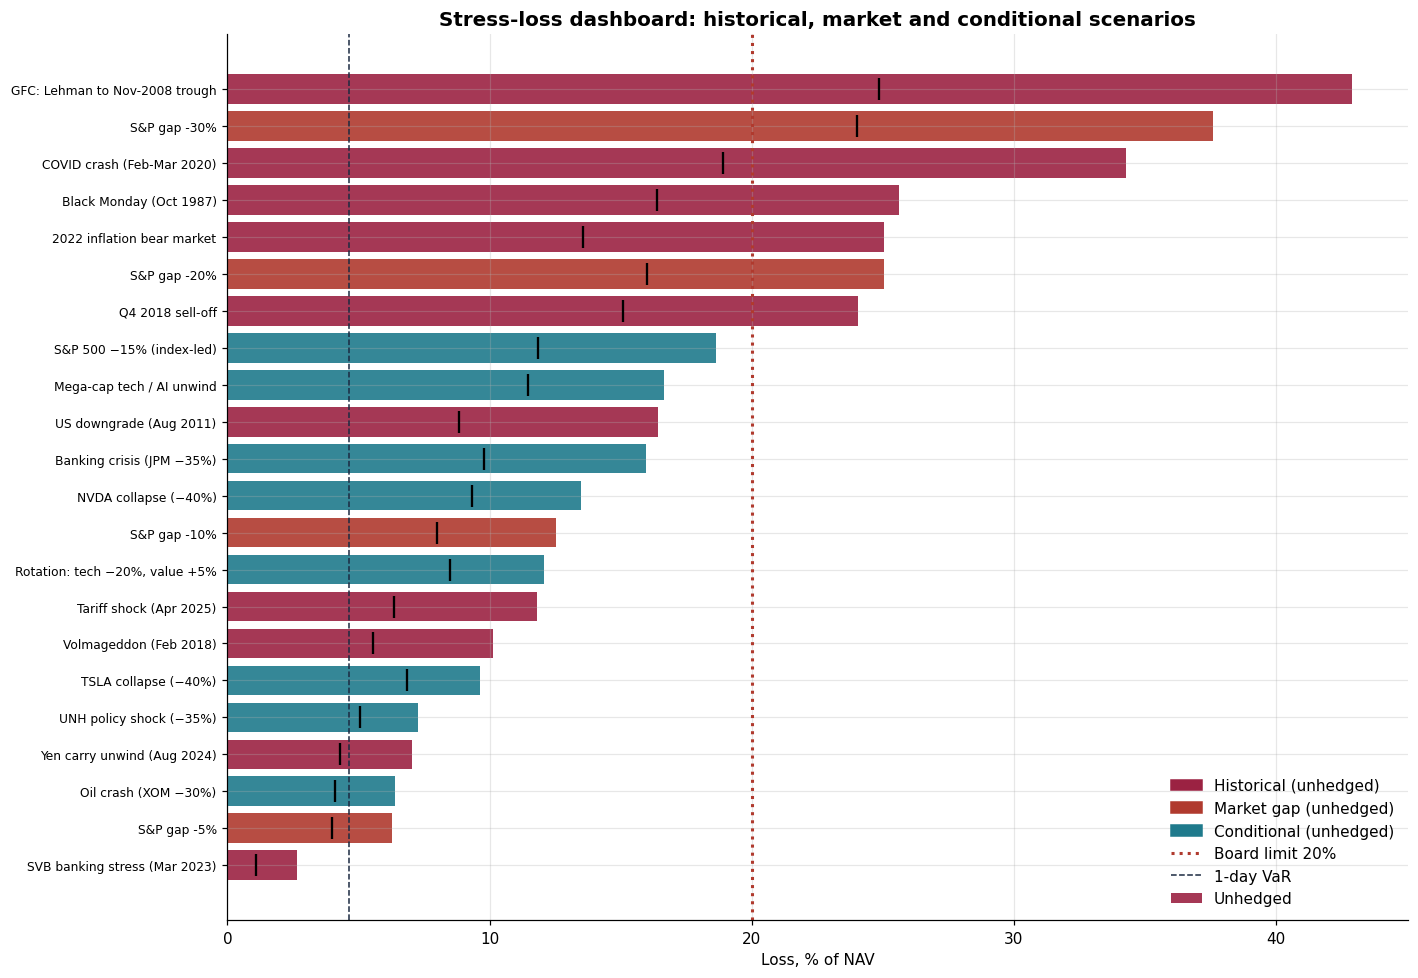

Hedge: short $2,045,126 of S&P 500 futures (45% of NAV). Scenarios over the limit: 7 -> 2.


,CAGR,Volatility,Max drawdown,Sharpe
Unhedged,28.6%,23.0%,-32.8%,1.21
Hedged to β 0.8,21.6%,16.3%,-24.3%,1.28


In [15]:
H = (BETA_DN_P - HEDGE_TARGET_BETA) * NAV          # short S&P notional
dash = pd.concat([
    HIST[HIST.Type != 'Worst window'].assign(Family='Historical', mkt=HIST['S&P 500'])[['Family', 'Loss $', 'mkt']],
    MKT.assign(Family='Market gap', **{'Loss $': MKT['Loss $ (downside beta)']}, mkt=MKT['S&P shock'])
       .set_index(MKT['S&P shock'].map(lambda s: f'S&P gap {s:.0%}'))[['Family', 'Loss $', 'mkt']],
    COND.assign(Family='Conditional', mkt=COND['S&P implied'])[['Family', 'Loss $', 'mkt']],
])
dash['Hedged loss $'] = dash['Loss $'] + H * dash['mkt']
dash['% NAV'] = dash['Loss $'] / NAV
dash['Hedged % NAV'] = dash['Hedged loss $'] / NAV
dash = dash.sort_values('Loss $')
fig, ax = plt.subplots(figsize=(13, 9))
y = np.arange(len(dash))
fc = dash['Family'].map({'Historical': '#9B2242', 'Market gap': COLORS['loss'], 'Conditional': COLORS['GARCH']})
ax.barh(y, dash['% NAV'] * 100, color=fc, alpha=0.9, label='Unhedged')
ax.scatter(dash['Hedged % NAV'] * 100, y, color='black', marker='|', s=200, zorder=5, label=f'With S&P hedge (target β {HEDGE_TARGET_BETA})')
ax.axvline(STRESS_LIMIT * 100, color=COLORS['loss'], ls=':', lw=2, label=f'Board limit {STRESS_LIMIT:.0%}')
ax.axvline(VAR1 / NAV * 100, color=COLORS['ink'], ls='--', lw=1, label='1-day VaR')
ax.set_yticks(y, dash.index, fontsize=8); ax.set_xlabel('Loss, % of NAV')
from matplotlib.patches import Patch
h_, l_ = ax.get_legend_handles_labels()
fam = [Patch(color=c_, label=f'{k_} (unhedged)') for k_, c_ in [('Historical', '#9B2242'), ('Market gap', COLORS['loss']), ('Conditional', COLORS['GARCH'])]]
ax.legend(handles=fam + h_[1:], loc='lower right')
ax.set_title('Stress-loss dashboard: historical, market and conditional scenarios')
plt.tight_layout(); plt.show()

# cost of the hedge over the actual 2020-2026 sample (daily-rebalanced to the same notional ratio)
hedged_r = returns - (H / NAV) * raw['Benchmark_Return'].reindex(returns.index).fillna(0) if 'Benchmark_Return' in raw else returns
def stats_(r):
    v = (1 + r).cumprod() * (raw['Value'].iloc[0] / INITIAL_VALUE)        # include day-0 cost, as in Task 3
    yrs = (r.index[-1] - raw.index[0]).days / 365.25
    return {'CAGR': v.iloc[-1] ** (1 / yrs) - 1, 'Volatility': r.std() * np.sqrt(TRADING_DAYS), 'Max drawdown': (v / v.cummax() - 1).min(),
            'Sharpe': r.mean() / r.std() * np.sqrt(TRADING_DAYS)}
HEDGE = pd.DataFrame({'Unhedged': stats_(returns), f'Hedged to β {HEDGE_TARGET_BETA}': stats_(hedged_r)}).T
n_breach, n_breach_h = int((dash['% NAV'] > STRESS_LIMIT).sum()), int((dash['Hedged % NAV'] > STRESS_LIMIT).sum())
print(f'Hedge: short {money(H)} of S&P 500 futures ({H / NAV:.0%} of NAV). Scenarios over the limit: {n_breach} -> {n_breach_h}.')
HEDGE.style.format({'CAGR': '{:.1%}', 'Volatility': '{:.1%}', 'Max drawdown': '{:.1%}', 'Sharpe': '{:.2f}'})

## 10. Exports

In [16]:
HIST.to_csv('Stress_Historical.csv'); COND.to_csv('Stress_Conditional.csv'); MKT.to_csv('Stress_Market.csv', index=False)
VC.to_csv('Stress_Vol_Correlation.csv'); RS.to_csv('Stress_Reverse.csv', index=False); dash.to_csv('Stress_Dashboard.csv')
SV.to_frame('Value').to_csv('Stressed_VaR.csv'); HEDGE.to_csv('Stress_Hedge.csv')
worst = dash['Loss $'].idxmax()
SUM = {'nav_usd': NAV, 'model': MODEL, 'var_1d_usd': VAR1, 'es_1d_usd': ES1, 'stressed_var_usd': float(SV['Stressed VaR $']),
       'stressed_window': SV['Stressed window'], 'worst_scenario': worst, 'worst_loss_usd': float(dash.loc[worst, 'Loss $']),
       'worst_loss_pct_nav': float(dash.loc[worst, '% NAV']), 'scenarios_over_limit': n_breach, 'limit_pct_nav': STRESS_LIMIT,
       'hedge_notional_usd': H, 'scenarios_over_limit_hedged': n_breach_h, 'author': AUTHOR, 'generated_at': datetime.now().isoformat(timespec='seconds')}
json.dump(SUM, open('Stress_Summary.json', 'w'), indent=2)
print('Saved: Stress_Historical, Stress_Conditional, Stress_Market, Stress_Vol_Correlation, Stress_Reverse, Stress_Dashboard,\n'
      '       Stressed_VaR, Stress_Hedge (.csv) and Stress_Summary.json')

Saved: Stress_Historical, Stress_Conditional, Stress_Market, Stress_Vol_Correlation, Stress_Reverse, Stress_Dashboard,
       Stressed_VaR, Stress_Hedge (.csv) and Stress_Summary.json


## 11. Executive summary: stress testing

In [17]:
gfc = HIST.loc['GFC: Lehman to Nov-2008 trough'] if 'GFC: Lehman to Nov-2008 trough' in HIST.index else None
cov = HIST.loc['COVID crash (Feb-Mar 2020)'] if 'COVID crash (Feb-Mar 2020)' in HIST.index else None
rs20 = RS[(RS.Loss == '20%') & (RS['Horizon (days)'] == 20)].iloc[0]
TB = "Today's book"
TOP5 = HIST[HIST.Type != 'Worst window']['x 1-day VaR'].nlargest(5)
gfc_line = (f"- **2008 GFC replayed** on today's holdings: {gfc[TB]:.1%} in {int(gfc.Days)} days (S&P {gfc['S&P 500']:.1%}); "
            f"{gfc['Proxied weight']:.0%} of the book was proxied.\n") if gfc is not None else ''
cov_line = (f"- **COVID crash replayed**: {cov[TB]:.1%} in {int(cov.Days)} days (S&P {cov['S&P 500']:.1%}), all with real stock data.\n") if cov is not None else ''
display(Markdown(f"""
**Book:** {money(NAV)}, downside beta **{BETA_DN_P:.2f}** (linear beta {BETA_P:.2f}). Production model: {MODEL}, 1-day 99% VaR **{money(VAR1)}** ({pct(VAR1 / NAV)} of NAV).

- **Worst scenario:** *{worst}*, with a loss of **{money(SUM['worst_loss_usd'])} ({SUM['worst_loss_pct_nav']:.0%} of NAV)**, about {SUM['worst_loss_usd'] / VAR1:.0f}x the daily VaR.
""" + gfc_line + cov_line + f"""
- **Stressed VaR** (worst year since 2007, {SV['Stressed window']}) is **{money(SV['Stressed VaR $'])}**, which is **{SV['sVaR / current model VaR']:.1f}x** today's model VaR.
- **Volatility at its peak plus crisis correlations** would raise 1-day VaR to **{money(VC.iloc[-1]['Stressed 1-day VaR $'])}** ({VC.iloc[-1]['VaR multiplier']:.1f}x).
- **Reverse stress:** a 20% loss needs an S&P fall of about {REV.iloc[2, 1]:.0%}. Over 20 days it is a {rs20['Distance (σ)']:.1f}σ event under normality, yet today's book
  did it in **{rs20['Distinct episodes']} separate episodes** since 2007 (last: {rs20['Last time']}).
- **Risk appetite:** {n_breach} scenarios exceed the illustrative {STRESS_LIMIT:.0%} limit. A short S&P hedge of {money(H)} cuts that to {n_breach_h},
  at the cost of CAGR {HEDGE.iloc[0]['CAGR']:.1%} → {HEDGE.iloc[1]['CAGR']:.1%} over 2020-26 (max drawdown {HEDGE.iloc[0]['Max drawdown']:.0%} → {HEDGE.iloc[1]['Max drawdown']:.0%}).

**Key message.** Daily VaR is about {pct(VAR1 / NAV)} of NAV. The five worst historical crises would cost today's book **{TOP5.min():.0f}–{TOP5.max():.0f}x that**
({(TOP5 * VAR1 / NAV).min():.0%}–{(TOP5 * VAR1 / NAV).max():.0%} of NAV). Most of the damage comes from the book's high-beta technology names (downside beta {BETA_DN_P:.2f}). VaR is the right tool for daily limits, and stress testing is what sizes the capital and the hedges.
"""))


**Book:** $4,520,228, downside beta **1.25** (linear beta 1.24). Production model: GJR-GARCH-FHS, 1-day 99% VaR **$210,395** (4.65% of NAV).

- **Worst scenario:** *GFC: Lehman to Nov-2008 trough*, with a loss of **$1,938,399 (43% of NAV)**, about 9x the daily VaR.
- **2008 GFC replayed** on today's holdings: -42.9% in 49 days (S&P -39.9%); 18% of the book was proxied.
- **COVID crash replayed**: -34.3% in 23 days (S&P -33.9%), all with real stock data.

- **Stressed VaR** (worst year since 2007, 05 Dec 2007 -> 02 Dec 2008) is **$389,926**, which is **1.9x** today's model VaR.
- **Volatility at its peak plus crisis correlations** would raise 1-day VaR to **$746,717** (3.5x).
- **Reverse stress:** a 20% loss needs an S&P fall of about 16%. Over 20 days it is a 3.2σ event under normality, yet today's book
  did it in **8 separate episodes** since 2007 (last: 2020-03-23).
- **Risk appetite:** 7 scenarios exceed the illustrative 20% limit. A short S&P hedge of $2,045,126 cuts that to 2,
  at the cost of CAGR 28.6% → 21.6% over 2020-26 (max drawdown -33% → -24%).

**Key message.** Daily VaR is about 4.65% of NAV. The five worst historical crises would cost today's book **5–9x that**
(24%–43% of NAV). Most of the damage comes from the book's high-beta technology names (downside beta 1.25). VaR is the right tool for daily limits, and stress testing is what sizes the capital and the hedges.


## 12. Project conclusion: Tasks 1–10 at a glance
This pulls the key result from every task's saved output, so the whole pipeline can be audited end to end.

In [18]:
def rd(f, **k):
    return pd.read_csv(f, **k) if os.path.exists(f) else None
q = rd('Data_Quality_Report.csv', index_col=0); sc = rd('Strategy_Comparison.csv', index_col=0)
dg = rd('Return_Diagnostics.csv', index_col=0); su = rd(SUMMARY_FILE); bt = rd('Backtest_Results.csv')
rec = json.load(open('Model_Recommendation.json')) if os.path.exists('Model_Recommendation.json') else {}
def g(fn, default='-'):
    try: return fn()
    except Exception: return default
head = lambda m: su.query('Model == @m and Window == @HEADLINE_W and Confidence == @HEADLINE_CL').iloc[0]
rows = [
    ('1 Data collection', g(lambda: f"{len(returns) + 1:,} trading days, 10 stocks + S&P 500; {(q['Status'] == 'OK').sum()}/10 tickers pass every quality check")),
    ('2 Data cleaning', g(lambda: f"no gaps; fat tails kept for VaR (portfolio excess kurtosis {dg.loc['Portfolio', 'Excess kurtosis']:.1f})")),
    ('3 Portfolio', g(lambda: f"$1M -> {money(NAV)}; CAGR {sc.loc['CAGR', 'Monthly rebalance']:.1%}, vol {sc.loc['Ann. volatility', 'Monthly rebalance']:.1%}, "
                              f"Sharpe {sc.loc['Sharpe', 'Monthly rebalance']:.2f}, max DD {sc.loc['Max drawdown', 'Monthly rebalance']:.1%}")),
    ('4 Historical Simulation', g(lambda: f"next-day VaR {money(head('HS')['Next-day VaR $'])}; reacts slowly, shows the ghost effect")),
    ('5 EWMA-FHS', g(lambda: f"next-day VaR {money(head('EWMA')['Next-day VaR $'])}; reacts much faster than HS after big losses")),
    ('6 GARCH-FHS', g(lambda: f"next-day VaR {money(head('GARCH')['Next-day VaR $'])}; estimated out of sample; volatility mean-reverts")),
    ('7 GJR-GARCH-FHS', g(lambda: f"next-day VaR {money(head('GJR')['Next-day VaR $'])}; leverage effect: losses move vol, gains barely do")),
    ('8 Backtesting', g(lambda: ', '.join(f"{m} {int((bt[bt.Model == m].Verdict == 'PASS').sum())}/9" for m in ['HS', 'EWMA', 'GARCH', 'GJR']) + ' cells pass')),
    ('9 Model selection', g(lambda: f"{rec['label']} (challenger {rec['challenger']}); 1-day VaR {money(rec['next_day_VaR_usd'])}, ES {money(rec['next_day_ES_usd'])}")),
    ('10 Stress testing', f"worst scenario {worst}: {money(SUM['worst_loss_usd'])} ({SUM['worst_loss_pct_nav']:.0%} NAV); stressed VaR {money(SUM['stressed_var_usd'])}"),
]
pd.DataFrame(rows, columns=['Task', 'Key result']).set_index('Task').style.set_properties(**{'text-align': 'left'})

,Key result
Task,
1 Data collection,"1,507 trading days, 10 stocks + S&P 500; 10/10 tickers pass every quality check"
2 Data cleaning,no gaps; fat tails kept for VaR (portfolio excess kurtosis 4.1)
3 Portfolio,"$1M -> $4,520,228; CAGR 28.6%, vol 23.0%, Sharpe 1.21, max DD -32.8%"
4 Historical Simulation,"next-day VaR $126,797; reacts slowly, shows the ghost effect"
5 EWMA-FHS,"next-day VaR $173,974; reacts much faster than HS after big losses"
6 GARCH-FHS,"next-day VaR $188,722; estimated out of sample; volatility mean-reverts"
7 GJR-GARCH-FHS,"next-day VaR $210,395; leverage effect: losses move vol, gains barely do"
8 Backtesting,"HS 3/9, EWMA 6/9, GARCH 5/9, GJR 7/9 cells pass"
9 Model selection,"GJR-GARCH-FHS (challenger EWMA); 1-day VaR $210,395, ES $247,131"


### Limitations
- **Linear, instantaneous revaluation.** The book is cash equity, so this is fair, but real crises unfold with liquidity costs and forced selling.
- **Proxies.** Pre-IPO and pre-2007 returns are downside-beta proxies with no stock-specific moves, and the share proxied is reported for every scenario.
- **Conditional scenarios** use 2020–2026 linear co-movements. In real crises correlations rise, so Section 7 stresses them separately.
- **Limits and hedge are illustrative.** A real board sets the risk appetite. The hedge ignores basis risk, margin and roll costs.

---
*Task 10 complete. This concludes the Market Risk Project: data, then portfolio, then four VaR models, then backtesting, model selection and stress testing.*

*Prepared by Arham Shah.*